# Track 03 Part 2 — corrected catch-up experiment

**Run in order with Kernel → Restart & Run All**, using the sprint repository's
Python environment. Place this notebook in `research/` in your existing clone.
It imports your merged `src.contrib.janice.leader_flow_impulse`; no new research
companion `.py` file is needed. Keep the original notebook as the first-run record.

This corrects measurement after the first full-panel result. It is **not a new
independent validation set or an untouched pre-registered first experiment**.
Record these corrections in your Issue/PR before rerunning. All comparisons remain
training-panel research; no fees, trading weights or strategy audit are computed.

## What changed

| Issue in the first notebook | Correction here |
|---|---|
| Unknown flow cutoff became “other” | Nullable classification; unknown hours excluded from both groups |
| 168h beta / 720h percentile allowed shorter warm-up | Full 168-return / 720-impulse history in the main result; shortened-history sensitivity shown separately |
| Strong-hour chart used the difference's SE | Separate joint-bootstrap intervals for each mean and each contrast; HAC uses the full covariance matrix |
| Control could use different hours | Both ICs use the exact same eligible hours and complete 18-alt cross-sections |
| Every-hth row selected after dropping observations | UTC epoch-hour phase selected before exclusions; **all** offsets reported |
| HAC bandwidth fixed to h | HAC bandwidth and block-bootstrap sensitivity, retaining the full hourly clock |
| Possible overinterpretation of positive IC / best horizon | Separate levels, strong-minus-other differences and paired control improvements; no automated winner or profitability claim |
| No full-feature causality check | Synthetic tests and real-panel prefix/future-perturbation checks |

The signal settings remain W=4, beta window=168, span=4, quantile=.9, percentile
window=720, horizons=1/2/4/8/24 and lags=0/1. Full warm-up and requiring all 18 names
are **explicit sample-policy corrections**, not assertions about the original plan.

**Delivery verification:** all code cells completed sequentially on synthetic data,
including 10 correctness tests, plots and result exports. Charts were visually
checked. Outputs are cleared for a fresh run. Real training data and the pinned
repository environment were not available for this verification.


In [1]:
import sys
from pathlib import Path

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src' / 'contrib' / 'janice.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside your sprint clone, where src/contrib/janice.py exists.')
sys.path.insert(0, str(ROOT))
from src.contrib.janice import leader_flow_impulse
import matplotlib.pyplot as plt
from IPython.display import display
print('Repository:', ROOT)


Repository: /Users/janicejizhe/Desktop/quant sprint/open-quant-sprint


## 1. Definitions and corrected statistical functions
Only `forward_returns` intentionally reads future observations, to create evaluation
labels. It must never be used inside `compute_weights`. Full feature functions use
only the current closed bar and earlier data. Do not globally suppress warnings.


In [2]:
from dataclasses import asdict, dataclass, replace
import hashlib
import json
import math
from pathlib import Path
import platform
import unittest

import numpy as np
import pandas as pd
from pandas.testing import assert_frame_equal, assert_series_equal

LEADERS = ('BTCUSDT', 'ETHUSDT')
HOUR_NS = 3_600_000_000_000


@dataclass(frozen=True)
class Params:
    gap_window: int = 4
    beta_window: int = 168
    impulse_span: int = 4
    strong_quantile: float = 0.9
    quantile_window: int = 720
    horizons: tuple = (1, 2, 4, 8, 24)
    lags: tuple = (0, 1)


@dataclass(frozen=True)
class Inference:
    bootstrap_reps: int = 1000
    block_hours: int = 168
    sensitivity_blocks: tuple = (24, 72, 168)
    sensitivity_hac: tuple = (24, 72, 168)
    min_group: int = 30
    seed: int = 20261116


def validate_panel(df):
    required = ['timestamp', 'symbol', 'close', 'quote_volume', 'taker_buy_quote_volume']
    if not set(required) <= set(df):
        raise ValueError('Missing columns: ' + str(sorted(set(required) - set(df))))
    d = df.copy()
    d['timestamp'] = pd.to_datetime(d['timestamp'], utc=True)
    if d.empty or d[['timestamp', 'symbol']].isna().any().any():
        raise ValueError('Empty panel or missing timestamp/symbol')
    if d.duplicated(['timestamp', 'symbol']).any():
        raise ValueError('Duplicate timestamp/symbol keys')
    names = set(d['symbol'])
    if len(names) != 20 or not set(LEADERS) <= names:
        raise ValueError('Expected BTC, ETH and exactly 18 alts')
    d = d.sort_values(['timestamp', 'symbol']).reset_index(drop=True)
    hours = pd.DatetimeIndex(d['timestamp'].unique())
    if not hours.equals(pd.date_range(hours[0], hours[-1], freq='h')):
        raise ValueError('Panel has missing hours; do not silently fill or compress time')
    if not (hours == hours.floor('h')).all() or not d.groupby('timestamp').size().eq(20).all():
        raise ValueError('Expected complete 20-symbol cross-sections on UTC hours')
    for col in required[2:]:
        d[col] = d[col].astype(float)
    if not np.isfinite(d[required[2:]].to_numpy()).all() or not d['close'].gt(0).all():
        raise ValueError('Non-finite data or nonpositive close')
    if not (d['quote_volume'].ge(0) & d['taker_buy_quote_volume'].ge(0)
            & d['taker_buy_quote_volume'].le(d['quote_volume'])).all():
        raise ValueError('Invalid volume bounds')
    return d


def wide(df, col):
    return df.pivot(index='timestamp', columns='symbol', values=col).sort_index()


def hourly_log_returns(df):
    return np.log(wide(df, 'close')).diff()


def rolling_beta(alt_rets, lead, window, min_periods=None):
    # Full windows by default. The optional shorter minimum is ONLY for the
    # explicitly labelled warm-up sensitivity check, not an automatic fallback.
    m = window if min_periods is None else min_periods
    cov = alt_rets.rolling(window, min_periods=m).cov(lead).shift(1)
    var = lead.rolling(window, min_periods=m).var().shift(1)
    return cov.div(var.where(var > 1e-12), axis=0)


def build_features(df, p, full_history=True):
    d = validate_panel(df)
    ret = hourly_log_returns(d)
    q = wide(d, 'quote_volume')[list(LEADERS)]
    lead = (ret[list(LEADERS)] * q).sum(axis=1, min_count=2).div(
        q.sum(axis=1).where(lambda v: v > 0))
    alts = ret.columns.difference(LEADERS)
    beta = rolling_beta(ret[alts], lead, p.beta_window,
                        None if full_history else p.beta_window // 2)
    alt_recent = ret[alts].rolling(p.gap_window).sum()
    lead_recent = lead.rolling(p.gap_window).sum()
    signal = -(alt_recent - beta.mul(lead_recent, axis=0))
    imp_rows = leader_flow_impulse(d, span=p.impulse_span)
    impulse = imp_rows.groupby(d['timestamp'], sort=True).first().reindex(ret.index)
    size = impulse.abs()
    minimum = p.quantile_window if full_history else p.quantile_window // 4
    cutoff = size.rolling(p.quantile_window, min_periods=minimum).quantile(p.strong_quantile).shift(1)
    eligible = size.notna() & cutoff.notna()
    # Unknown is pd.NA, NOT False. It stays out of both comparison groups.
    strong = size.gt(cutoff).astype('boolean').where(eligible, pd.NA).rename('strong')
    return dict(signal=signal, reversal=-alt_recent, beta=beta, lead=lead,
                returns=ret[alts], impulse=impulse, cutoff=cutoff, strong=strong)


def forward_returns(rets, h, lag):
    # RESEARCH LABEL ONLY: returns from close(t+lag) to close(t+lag+h).
    return rets.rolling(h).sum().shift(-(h + lag))


def xs_rank_ic(signal, target):
    # Require the complete 18-alt cross-section; ties use average ranks.
    valid = np.isfinite(signal).all(axis=1) & np.isfinite(target).all(axis=1)
    x, y = signal.rank(axis=1), target.rank(axis=1)
    dx, dy = x.sub(x.mean(axis=1), axis=0), y.sub(y.mean(axis=1), axis=0)
    den = np.sqrt(dx.pow(2).sum(axis=1) * dy.pow(2).sum(axis=1))
    return ((dx * dy).sum(axis=1) / den.where(den > 1e-12)).where(valid)


def paired_ic_frame(features, h, lag):
    target = forward_returns(features['returns'], h, lag)
    gap = xs_rank_ic(features['signal'], target)
    reversal = xs_rank_ic(features['reversal'], target)
    group = features['strong'].reindex(gap.index)
    common = np.isfinite(gap) & np.isfinite(reversal) & group.notna()
    return pd.DataFrame({'gap': gap.where(common), 'reversal': reversal.where(common),
                         'strong': group}, index=gap.index)


METRICS = ('gap_all', 'gap_strong', 'gap_other', 'reversal_all', 'reversal_strong',
           'reversal_other', 'gap_difference', 'reversal_difference',
           'paired_all', 'paired_strong', 'paired_other')


def contributions(frame):
    # Keep the COMPLETE clock. Missing observations contribute zero to both
    # numerator and count; never glue separated valid hours together.
    y = frame[['gap', 'reversal']].to_numpy(dtype=float)
    valid = np.isfinite(y).all(axis=1) & frame['strong'].notna().to_numpy()
    s = frame['strong'].fillna(False).to_numpy(dtype=bool)
    masks = np.column_stack([valid, valid & s, valid & ~s]).astype(float)
    yy = np.nan_to_num(y, nan=0.0)
    return np.column_stack([masks * yy[:, [0]], masks * yy[:, [1]], masks])


def metrics_from_totals(total):
    total = np.asarray(total)
    count = total[..., 6:9]
    a = np.divide(total[..., :3], count, out=np.full_like(count, np.nan), where=count > 0)
    b = np.divide(total[..., 3:6], count, out=np.full_like(count, np.nan), where=count > 0)
    return np.concatenate([a, b, (a[..., 1]-a[..., 2])[..., None],
                           (b[..., 1]-b[..., 2])[..., None], a-b], axis=-1)


def point_estimates(frame):
    total = contributions(frame).sum(axis=0)
    row = dict(zip(METRICS, metrics_from_totals(total)))
    row.update(n_all=int(total[6]), n_strong=int(total[7]), n_other=int(total[8]),
               n_clock=len(frame), n_excluded=int(len(frame)-total[6]))
    return row


def bootstrap(frame, block, reps, seed, min_group=30):
    """Joint circular moving-block bootstrap; same draws for both signals.

    Efficient exact sums of circular blocks retain group/invalid-hour alignment.
    Blocks are in actual HOURS, not a compressed list of strong observations.
    """
    a = contributions(frame)
    n = len(a)
    ci = {f'{m}_{side}': np.nan for m in METRICS for side in ('low', 'high')}
    total = a.sum(axis=0)
    if n < 2*block or total[7] < min_group or total[8] < min_group:
        return ci
    rng = np.random.default_rng(seed)
    full, rem = divmod(n, block)
    circular = np.concatenate([a, a[:block]], axis=0)
    cumulative = np.vstack([np.zeros((1, 9)), np.cumsum(circular, axis=0)])
    starts = rng.integers(0, n, size=(reps, full))
    samples = (cumulative[starts+block] - cumulative[starts]).sum(axis=1)
    if rem:
        tail = rng.integers(0, n, size=reps)
        samples += cumulative[tail+rem] - cumulative[tail]
    draws = metrics_from_totals(samples)
    for j, metric in enumerate(METRICS):
        values = draws[:, j]
        values = values[np.isfinite(values)]
        if len(values) >= .9*reps:
            ci[f'{metric}_low'], ci[f'{metric}_high'] = np.quantile(values, [.025, .975])
    return ci


def hac_covariance_on_clock(y, strong, n_lags):
    """OLS on [1,strong], Bartlett HAC retaining zero scores in missing hours."""
    y = np.asarray(y, dtype=float)
    group = pd.Series(strong).reset_index(drop=True)
    valid = np.isfinite(y) & group.notna().to_numpy()
    s = group.fillna(False).to_numpy(dtype=float)
    if (valid & (s == 1)).sum() < 2 or (valid & (s == 0)).sum() < 2:
        return np.full(2, np.nan), np.full((2, 2), np.nan)
    X = np.column_stack([np.ones(len(y)), s])
    bread = np.linalg.inv(X[valid].T @ X[valid])
    b = bread @ X[valid].T @ y[valid]
    scores = np.zeros_like(X)
    scores[valid] = X[valid] * (y[valid] - X[valid] @ b)[:, None]
    meat = scores.T @ scores
    for k in range(1, min(n_lags, len(y)-1)+1):
        w = 1 - k/(n_lags+1)
        G = scores[k:].T @ scores[:-k]
        meat += w*(G+G.T)
    return b, bread @ meat @ bread


def contrast_se(cov, contrast):
    v = np.asarray(contrast, dtype=float)
    variance = float(v @ cov @ v)
    return np.sqrt(max(variance, 0)) if np.isfinite(variance) else np.nan


def hac_sensitivity(frame, bandwidths):
    rows = []
    for L in sorted(set(bandwidths)):
        for name, y in [('gap', frame['gap']), ('reversal', frame['reversal']),
                        ('paired', frame['gap']-frame['reversal'])]:
            b, cov = hac_covariance_on_clock(y, frame['strong'], L)
            for group, c in [('other', [1, 0]), ('strong', [1, 1]), ('difference', [0, 1])]:
                estimate = float(np.asarray(c) @ b)
                se = contrast_se(cov, c)
                rows.append(dict(bandwidth=L, signal=name, group=group, estimate=estimate,
                                 se=se, low=estimate-1.96*se, high=estimate+1.96*se))
    return pd.DataFrame(rows)


def nonoverlap_offsets(frame, h):
    # Phase comes from epoch-hour BEFORE any missing-data exclusion.
    hour = frame.index.as_unit('ns').asi8 // HOUR_NS
    return pd.DataFrame([dict(offset=offset, **point_estimates(frame.loc[hour % h == offset]))
                         for offset in range(h)])


def quarterly_summary(frame):
    q = frame.index.tz_localize(None).to_period('Q')
    return pd.DataFrame([dict(quarter=str(label), **point_estimates(part))
                         for label, part in frame.groupby(q)]).set_index('quarter')


def feature_causality_checks(df, p):
    """No future labels here: verify features on prefixes and perturbed futures."""
    full = build_features(df, p)
    hours = full['signal'].index
    if len(hours) <= max(p.quantile_window, p.beta_window) + 2:
        raise ValueError('Need more history for meaningful post-warm-up causality checks')
    cuts = sorted(set([len(hours)//2, int(.85*len(hours)), len(hours)-2]))
    for k in cuts:
        short = build_features(df.loc[pd.to_datetime(df['timestamp'], utc=True) <= hours[k]], p)
        for key in ('signal', 'reversal', 'beta', 'returns'):
            assert_frame_equal(short[key], full[key].iloc[:k+1], atol=1e-10, rtol=0)
        for key in ('impulse', 'cutoff', 'strong'):
            assert_series_equal(short[key], full[key].iloc[:k+1], check_exact=False, atol=1e-12, rtol=0)
    k = len(hours)//2
    changed = df.copy()
    future = pd.to_datetime(changed['timestamp'], utc=True) > hours[k]
    changed.loc[future, 'close'] *= 1.4
    changed.loc[future, 'taker_buy_quote_volume'] = changed.loc[future, 'quote_volume']
    perturbed = build_features(changed, p)
    for key in ('signal', 'reversal', 'beta'):
        assert_frame_equal(full[key].iloc[:k+1], perturbed[key].iloc[:k+1], atol=1e-10, rtol=0)
    for key in ('impulse', 'cutoff', 'strong'):
        assert_series_equal(full[key].iloc[:k+1], perturbed[key].iloc[:k+1])
    repeat = build_features(df, p)
    assert_frame_equal(repeat['signal'], full['signal'])
    assert_series_equal(repeat['strong'], full['strong'])
    return f'PASS: {len(cuts)} prefix cuts, future perturbation and determinism; features only.'


def synthetic_panel(n=1500, seed=41):
    rng = np.random.default_rng(seed)
    hours = pd.date_range('2026-01-01', periods=n, freq='h', tz='UTC')
    symbols = list(LEADERS) + [f'ALT{i:02d}USDT' for i in range(18)]
    common = rng.normal(0, .003, n)
    r = common[:, None] * np.linspace(.8, 1.8, 20) + rng.normal(0, .002, (n, 20))
    prices = 100*np.exp(np.cumsum(r, axis=0))
    qv = rng.uniform(100, 10000, (n, 20))
    flow = rng.uniform(.03, .97, (n, 20))
    out = pd.MultiIndex.from_product([hours, symbols], names=['timestamp', 'symbol']).to_frame(index=False)
    out['close'], out['quote_volume'], out['taker_buy_quote_volume'] = prices.ravel(), qv.ravel(), (qv*flow).ravel()
    return out


def hash_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


## 2. Settings and correction record
`USE_REAL_DATA=True` reads the existing training file. Switch it to False only for a
synthetic plumbing check; synthetic performance numbers have no market meaning.

The main intervals use jointly resampled 168-hour circular blocks, preserving the
alignment of both signals, group membership and missing observations. We also show
24/72/168-hour block and HAC sensitivity. These are approximate **pointwise 95%**
intervals, not a multiple-testing correction across ten horizon/lag cells. Longer
blocks are sensitivity choices, not guaranteed optimal dependence models. Do not
select the interval or horizon that looks most favorable.


In [3]:
USE_REAL_DATA = True
P = Params()
I = Inference()
DATA_PATH = ROOT / 'data' / 'train_1h.parquet'
print('Signal settings:', json.dumps(asdict(P), indent=2))
print('Inference settings:', json.dumps(asdict(I), indent=2))
print('Main history policy: FULL windows; unknown group excluded; common 18-alt sample.')


Signal settings: {
  "gap_window": 4,
  "beta_window": 168,
  "impulse_span": 4,
  "strong_quantile": 0.9,
  "quantile_window": 720,
  "horizons": [
    1,
    2,
    4,
    8,
    24
  ],
  "lags": [
    0,
    1
  ]
}
Inference settings: {
  "bootstrap_reps": 1000,
  "block_hours": 168,
  "sensitivity_blocks": [
    24,
    72,
    168
  ],
  "sensitivity_hac": [
    24,
    72,
    168
  ],
  "min_group": 30,
  "seed": 20261116
}
Main history policy: FULL windows; unknown group excluded; common 18-alt sample.


## 3. Correctness tests — synthetic data only
These check beta against an independent two-pass calculation, lagged labels,
unknown warm-up classification, paired sample eligibility, UTC sampling offsets,
the full HAC covariance contrast and bootstrap block sums against explicit draws.
They also check feature causality. A failed check stops execution.


In [4]:
class CorrectionTests(unittest.TestCase):
    def setUp(self):
        self.p = Params(beta_window=24, quantile_window=48)

    def test_full_history_and_unknown_warmup(self):
        f = build_features(synthetic_panel(140), self.p)
        self.assertTrue(f['strong'].iloc[:48].isna().all())
        self.assertTrue(f['strong'].iloc[48:].notna().all())
        self.assertTrue(f['beta'].iloc[:25].isna().all().all())
        frame = paired_ic_frame(f, 1, 0)
        self.assertTrue(frame['gap'].iloc[:48].isna().all())
        row = point_estimates(frame)
        self.assertEqual(row['n_strong']+row['n_other'], row['n_all'])

    def test_beta_two_pass_reference_and_timing(self):
        rng = np.random.default_rng(8)
        x = pd.Series(rng.normal(0, .01, 100))
        y = pd.DataFrame({'a': 1.8*x+rng.normal(0, .003, 100)})
        result = rolling_beta(y, x, 24)
        for t in (24, 25, 60, 99):
            xx = x.iloc[t-24:t].to_numpy()
            yy = y['a'].iloc[t-24:t].to_numpy()
            reference = np.dot(xx-xx.mean(), yy-yy.mean())/np.dot(xx-xx.mean(), xx-xx.mean())
            self.assertAlmostEqual(result.loc[t, 'a'], reference, places=12)
        altered = y.copy()
        altered.loc[60, 'a'] += 20
        self.assertAlmostEqual(rolling_beta(altered, x, 24).loc[60, 'a'], result.loc[60, 'a'])

    def test_full_feature_causality(self):
        result = feature_causality_checks(synthetic_panel(150), self.p)
        self.assertTrue(result.startswith('PASS'))

    def test_labels_and_rank_ic(self):
        r = pd.DataFrame({'a': [1., 2., 3., 4., 5., 6.]})
        self.assertEqual(forward_returns(r, 2, 1).iloc[0, 0], 7.)
        x = pd.DataFrame([np.arange(18), np.arange(18), np.ones(18)], dtype=float)
        y = pd.DataFrame([np.arange(18), -np.arange(18), np.arange(18)], dtype=float)
        out = xs_rank_ic(x, y)
        np.testing.assert_allclose(out.iloc[:2], [1., -1.], atol=1e-14)
        self.assertTrue(np.isnan(out.iloc[2]))

    def test_identical_eligibility_for_control(self):
        f = build_features(synthetic_panel(160), self.p)
        f['signal'].iloc[90, 0] = np.nan
        frame = paired_ic_frame(f, 4, 1)
        self.assertTrue(np.isnan(frame['gap'].iloc[90]))
        self.assertTrue(np.isnan(frame['reversal'].iloc[90]))
        self.assertTrue(frame['gap'].notna().equals(frame['reversal'].notna()))

    def test_fixed_clock_all_offsets_with_internal_missing(self):
        idx = pd.date_range('2026-01-01', periods=32, freq='h', tz='UTC')
        d = pd.DataFrame({'gap': .1, 'reversal': .05,
                          'strong': pd.array(np.arange(32)%3 == 0, dtype='boolean')}, index=idx)
        d.loc[idx[5], ['gap', 'reversal']] = np.nan
        offsets = nonoverlap_offsets(d, 4)
        self.assertTrue(offsets['n_clock'].eq(8).all())
        self.assertEqual(offsets.loc[1, 'n_all'], 7)
        self.assertEqual(offsets['n_all'].sum(), 31)

    def test_paired_estimate_is_direct_difference(self):
        idx = pd.date_range('2026-01-01', periods=12, freq='h', tz='UTC')
        d = pd.DataFrame({'gap': np.arange(12)*.01, 'reversal': .02,
                          'strong': pd.array(np.arange(12)%2 == 0, dtype='boolean')}, index=idx)
        out = point_estimates(d)
        self.assertAlmostEqual(out['paired_strong'], (d.loc[d['strong'], 'gap']-.02).mean())

    def test_hac_strong_contrast_and_covariance(self):
        rng = np.random.default_rng(12)
        s = pd.Series(np.arange(300)%4 == 0, dtype='boolean')
        y = rng.normal(0, .2, 300) + .03*s.to_numpy(dtype=float)
        y[13] = np.nan
        b, cov = hac_covariance_on_clock(y, s, 12)
        valid = np.isfinite(y)
        X = np.column_stack([np.ones(300), s.to_numpy(dtype=float)])
        bread = np.linalg.inv(X[valid].T@X[valid])
        u = np.zeros(300)
        u[valid] = y[valid]-X[valid]@b
        score = X*u[:, None]
        meat = sum(np.outer(v, v) for v in score)
        for k in range(1, 13):
            for t in range(k, 300):
                product = np.outer(score[t], score[t-k])
                meat += (1-k/13)*(product+product.T)
        np.testing.assert_allclose(cov, bread@meat@bread, atol=1e-14)
        self.assertAlmostEqual(contrast_se(cov, [1, 1])**2,
                               cov[0, 0]+cov[1, 1]+2*cov[0, 1])

    def test_bootstrap_block_sums_equal_explicit_resampling(self):
        rng = np.random.default_rng(22)
        idx = pd.date_range('2026-01-01', periods=60, freq='h', tz='UTC')
        d = pd.DataFrame({'gap': rng.normal(0, .1, 60), 'reversal': rng.normal(0, .1, 60),
                          'strong': pd.array(np.arange(60)%3 == 0, dtype='boolean')}, index=idx)
        d.loc[idx[9], ['gap', 'reversal']] = np.nan
        n, block, reps, seed = 60, 7, 80, 123
        got = bootstrap(d, block, reps, seed, min_group=1)
        a = contributions(d)
        full, rem = divmod(n, block)
        random = np.random.default_rng(seed)
        starts = random.integers(0, n, size=(reps, full))
        tails = random.integers(0, n, size=reps)
        draw = []
        for j in range(reps):
            ix = np.concatenate([((starts[j, :, None]+np.arange(block))%n).ravel(),
                                 (tails[j]+np.arange(rem))%n])
            draw.append(metrics_from_totals(a[ix].sum(axis=0)))
        expected = np.quantile(np.array(draw), [.025, .975], axis=0)
        for j, name in enumerate(METRICS):
            np.testing.assert_allclose([got[name+'_low'], got[name+'_high']], expected[:, j], atol=1e-12)

    def test_invalid_panels_and_insufficient_groups(self):
        df = synthetic_panel(80)
        for bad in (df.iloc[1:], pd.concat([df, df.iloc[[0]]])):
            with self.assertRaises(ValueError):
                validate_panel(bad)
        f = build_features(df, self.p)
        frame = paired_ic_frame(f, 1, 0)
        frame['strong'] = pd.Series(False, index=frame.index, dtype='boolean')
        ci = bootstrap(frame, block=12, reps=20, seed=1)
        self.assertTrue(all(np.isnan(v) for v in ci.values()))


test_result = unittest.TextTestRunner(verbosity=1).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(CorrectionTests))
assert test_result.wasSuccessful(), 'Correctness checks failed; stop before interpreting results.'


..........
----------------------------------------------------------------------
Ran 10 tests in 0.200s

OK


## 4. Load data and build the corrected causal inputs
The source panel must be contiguous, hourly and balanced with BTC/ETH plus 18 alts.
No future fill or silent compression of the time axis is allowed. Return-beta
history excludes t; the 30-day cutoff also ends at t-1. The first 720 hours cannot
be classified with a complete cutoff and are excluded, rather than called weak.

Bar timestamps label **opens**. A bar's volumes and close are available at its
close. Lag 1 labels start one additional bar later than lag 0.


REAL training panel — corrected reanalysis (297420, 11)


rows                                    297420.00000
hours                                    14871.00000
alts                                        18.00000
unknown_flow_hours                         720.00000
eligible_flow_hours                      14151.00000
strong_hours_before_label_exclusions      1455.00000
strong_fraction_among_classified             0.10282
complete_signal_hours                    14702.00000
Name: coverage, dtype: float64

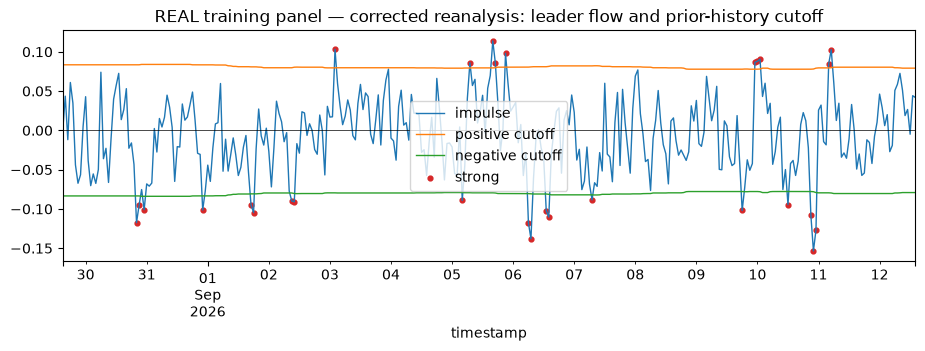

In [5]:
if USE_REAL_DATA:
    df = pd.read_parquet(DATA_PATH)
    data_label = 'REAL training panel — corrected reanalysis'
else:
    df = synthetic_panel(1500)
    data_label = 'SYNTHETIC plumbing check — not a market result'
df = validate_panel(df)
F = build_features(df, P)
eligible_flow = F['strong'].notna()
diagnostics = pd.Series({
    'rows': len(df), 'hours': len(F['signal']), 'alts': F['signal'].shape[1],
    'unknown_flow_hours': int((~eligible_flow).sum()),
    'eligible_flow_hours': int(eligible_flow.sum()),
    'strong_hours_before_label_exclusions': int(F['strong'].sum()),
    'strong_fraction_among_classified': float(F['strong'].dropna().mean()),
    'complete_signal_hours': int(F['signal'].notna().all(axis=1).sum()),
}, name='coverage')
print(data_label, df.shape)
display(diagnostics)

plot_frame = pd.DataFrame({'impulse': F['impulse'], 'positive cutoff': F['cutoff'],
                           'negative cutoff': -F['cutoff']}).tail(24*14)
ax = plot_frame.plot(figsize=(11, 3), lw=1)
selected = F['impulse'].where(F['strong'].fillna(False)).reindex(plot_frame.index)
ax.scatter(selected.index, selected, s=12, color='C3', label='strong')
ax.axhline(0, color='black', lw=.5)
ax.set_title(data_label + ': leader flow and prior-history cutoff')
ax.legend(); plt.show()


## 5. Full-feature causality checks on the loaded panel
This recomputes on three prefixes, changes future prices/volumes and checks that
historical features do not change. It also checks repeated-call determinism.
Future-return labels are correctly excluded from these checks.


In [6]:
causality_result = feature_causality_checks(df, P)
print(causality_result)


PASS: 3 prefix cuts, future perturbation and determinism; features only.


## 6. Main results — both signals on identical eligible hours
`gap_difference = gap_strong - gap_other` tests whether strong flow improves the
gap signal. `paired_strong = gap_strong - reversal_strong` tests whether beta
adjustment improves on plain reversal in strong hours. IC is a rank correlation,
**not a return, probability of a winning trade, or Sharpe ratio**.

Missing, incomplete and constant-ranking cross-sections are excluded identically
for both signals. A minimum of 30 observations per group and two block lengths
is required for bootstrap intervals; this is a reporting guard, not a guarantee of
adequate statistical power. Undefined intervals stay NaN, never zero.


In [7]:
frames, summary_rows = {}, []
for lag in P.lags:
    for h in P.horizons:
        frame = paired_ic_frame(F, h, lag)
        frames[(lag, h)] = frame
        estimates = point_estimates(frame)
        intervals = bootstrap(frame, I.block_hours, I.bootstrap_reps,
                              I.seed + 100*lag + h, I.min_group)
        summary_rows.append(dict(lag=lag, h=h, **estimates, **intervals))
summary = pd.DataFrame(summary_rows).set_index(['lag', 'h'])
display(summary[['gap_other', 'gap_strong', 'gap_difference',
                 'gap_difference_low', 'gap_difference_high',
                 'n_other', 'n_strong', 'n_excluded']].round(5))


gap_other  gap_strong  gap_difference  gap_difference_low  \
lag h                                                               
0   1     0.03096     0.01407        -0.01689            -0.03357   
    2     0.03431     0.01462        -0.01969            -0.03861   
    4     0.03028     0.02544        -0.00485            -0.02251   
    8     0.02689     0.02074        -0.00616            -0.02501   
    24    0.02054     0.01662        -0.00393            -0.02280   
1   1     0.01898     0.00626        -0.01272            -0.02929   
    2     0.01979     0.01887        -0.00092            -0.01884   
    4     0.01811     0.01918         0.00108            -0.01704   
    8     0.01986     0.02052         0.00066            -0.01833   
    24    0.01640     0.01532        -0.00109            -0.01959   

        gap_difference_high  n_other  n_strong  n_excluded  
lag h                                                       
0   1              -0.00086    12695      1455         721  
    2              -0.00151    12694      1455         722  
    4               0.01316    12692      1455         724  
    8               0.01198    12688      1455         728  
    24              0.01578    12672      1455         744  
1   1               0.00378    12694      1455         722  
    2               0.01580    12693      1455         723  
    4               0.01922    12691      1455         725  
    8               0.01873    12687      1455         729  
    24              0.01710    12671      1455         745

## 7. Corrected IC curves and strong-minus-other contrasts
Each shaded band now belongs to **the mean or contrast actually plotted**.
The reversal control uses the same sample; its separate intervals are available
in `summary`. A level can be positive while its strong-minus-other difference
is near zero. These are different research claims.


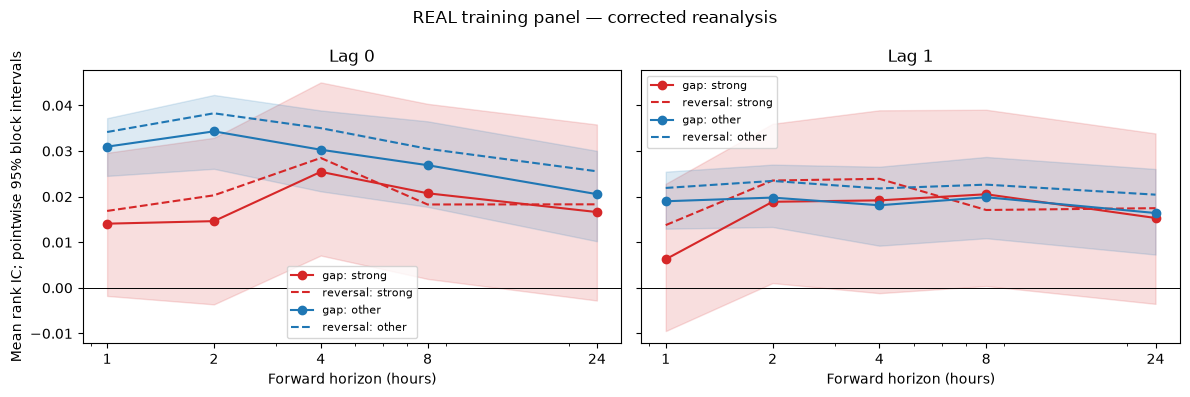

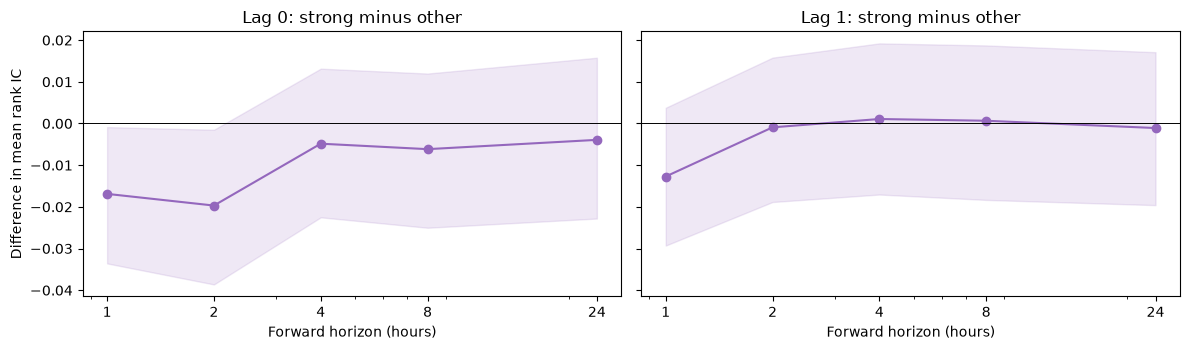

In [8]:
fig, axes = plt.subplots(1, len(P.lags), figsize=(6*len(P.lags), 4), sharey=True)
for ax, lag in zip(np.atleast_1d(axes), P.lags):
    s = summary.loc[lag]
    x = np.asarray(s.index, dtype=float)
    for group, color in [('strong', 'C3'), ('other', 'C0')]:
        y = s['gap_'+group].to_numpy(dtype=float)
        ax.plot(x, y, 'o-', color=color, label='gap: '+group)
        ax.fill_between(x, s['gap_'+group+'_low'].to_numpy(dtype=float),
                        s['gap_'+group+'_high'].to_numpy(dtype=float), color=color, alpha=.15)
        ax.plot(x, s['reversal_'+group], '--', color=color, label='reversal: '+group)
    ax.axhline(0, color='black', lw=.7)
    ax.set_xscale('log'); ax.set_xticks(x); ax.set_xticklabels(P.horizons)
    ax.set_xlabel('Forward horizon (hours)'); ax.set_title(f'Lag {lag}')
    ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel('Mean rank IC; pointwise 95% block intervals')
fig.suptitle(data_label); fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(P.lags), figsize=(6*len(P.lags), 3.6), sharey=True)
for ax, lag in zip(np.atleast_1d(axes), P.lags):
    s = summary.loc[lag]; x = np.asarray(s.index, dtype=float)
    ax.plot(x, s['gap_difference'], 'o-', color='C4')
    ax.fill_between(x, s['gap_difference_low'].to_numpy(dtype=float),
                    s['gap_difference_high'].to_numpy(dtype=float), color='C4', alpha=.15)
    ax.axhline(0, color='black', lw=.7)
    ax.set_xscale('log'); ax.set_xticks(x); ax.set_xticklabels(P.horizons)
    ax.set_xlabel('Forward horizon (hours)'); ax.set_title(f'Lag {lag}: strong minus other')
np.atleast_1d(axes)[0].set_ylabel('Difference in mean rank IC')
fig.tight_layout(); plt.show()


## 8. Paired test: does beta adjustment improve on plain reversal?
Subtract the two hourly ICs first, then assess their mean on the same observations.
The joint bootstrap uses identical time draws for both signals, preserving their
dependence. This is stronger evidence than comparing two unrelated averages or
judging overlap between separate confidence bands.


In [9]:
display(summary[['gap_strong', 'reversal_strong', 'paired_strong',
                 'paired_strong_low', 'paired_strong_high',
                 'paired_other', 'paired_other_low', 'paired_other_high']].round(5))


gap_strong  reversal_strong  paired_strong  paired_strong_low  \
lag h                                                                   
0   1      0.01407          0.01686       -0.00279           -0.00998   
    2      0.01462          0.02029       -0.00566           -0.01266   
    4      0.02544          0.02848       -0.00304           -0.01086   
    8      0.02074          0.01828        0.00246           -0.00590   
    24     0.01662          0.01831       -0.00170           -0.01124   
1   1      0.00626          0.01376       -0.00749           -0.01437   
    2      0.01887          0.02353       -0.00466           -0.01249   
    4      0.01918          0.02391       -0.00472           -0.01268   
    8      0.02052          0.01707        0.00345           -0.00400   
    24     0.01532          0.01747       -0.00215           -0.01277   

        paired_strong_high  paired_other  paired_other_low  paired_other_high  
lag h                                                                          
0   1              0.00442      -0.00321          -0.00504           -0.00112  
    2              0.00127      -0.00396          -0.00669           -0.00137  
    4              0.00447      -0.00473          -0.00766           -0.00178  
    8              0.01056      -0.00360          -0.00665           -0.00061  
    24             0.00795      -0.00501          -0.00840           -0.00158  
1   1             -0.00063      -0.00292          -0.00485           -0.00085  
    2              0.00318      -0.00365          -0.00612           -0.00113  
    4              0.00319      -0.00369          -0.00653           -0.00123  
    8              0.01075      -0.00277          -0.00576            0.00035  
    24             0.00756      -0.00403          -0.00748           -0.00036

## 9. Nonoverlapping returns — every fixed UTC offset
For h=4, offsets 0/1/2/3 mean hours whose UTC epoch-hour remainder is 0/1/2/3.
Phase is determined before any exclusion. Each phase has nonoverlapping forward
windows, including at lag 1. Different phases still share market information and
are **not independent replications**. Report all phases; do not choose the best.


In [10]:
offset_tables = []
for (lag, h), frame in frames.items():
    offsets = nonoverlap_offsets(frame, h)
    offsets.insert(0, 'h', h); offsets.insert(0, 'lag', lag)
    offset_tables.append(offsets)
offsets = pd.concat(offset_tables, ignore_index=True)
display(offsets[['lag', 'h', 'offset', 'gap_difference', 'paired_strong',
                 'n_strong', 'n_other']].round(5))
offset_ranges = offsets.groupby(['lag', 'h']).agg(
    difference_min=('gap_difference', 'min'), difference_max=('gap_difference', 'max'),
    smallest_strong_sample=('n_strong', 'min'), largest_strong_sample=('n_strong', 'max'))
display(offset_ranges.round(5))


,lag,h,offset,gap_difference,paired_strong,n_strong,n_other
0,0,1,0,-0.01689,-0.00279,1455,12695
1,0,2,0,-0.02958,-0.00799,733,6342
2,0,2,1,-0.00965,-0.00330,722,6352
3,0,4,0,-0.00972,-0.01005,363,3174
4,0,4,1,0.02523,-0.00704,370,3167
...,...,...,...,...,...,...,...
73,1,24,19,0.00718,0.00840,58,530
74,1,24,20,-0.03627,-0.02830,69,519
75,1,24,21,0.01653,0.00376,69,519
76,1,24,22,-0.00847,0.00151,81,507


difference_min  difference_max  smallest_strong_sample  \
lag h                                                            
0   1         -0.01689        -0.01689                    1455   
    2         -0.02958        -0.00965                     722   
    4         -0.02227         0.02523                     352   
    8         -0.04455         0.03854                     169   
    24        -0.04976         0.13643                      29   
1   1         -0.01272        -0.01272                    1455   
    2         -0.01185         0.01016                     722   
    4         -0.01981         0.04769                     352   
    8         -0.03714         0.04620                     169   
    24        -0.04714         0.13228                      29   

        largest_strong_sample  
lag h                          
0   1                    1455  
    2                     733  
    4                     370  
    8                     200  
    24                     83  
1   1                    1455  
    2                     733  
    4                     370  
    8                     200  
    24                     83

## 10. Dependence-model sensitivity: HAC and block lengths
HAC uses the full 2×2 coefficient covariance matrix. In particular,
Var(strong mean)=Var(b0)+Var(b1)+2Cov(b0,b1), not Var(b1).
Unknown/invalid hours retain zero scores on the original hourly clock rather
than compressing distant hours together. We show bandwidth h and 24/72/168.
The bootstrap resamples complete time blocks jointly for both ICs/groups.
Inspect sensitivity; do not report only whichever method gives the smallest band.


In [11]:
hac_tables, block_rows = [], []
for (lag, h), frame in frames.items():
    table = hac_sensitivity(frame, [h, *I.sensitivity_hac])
    table.insert(0, 'h', h); table.insert(0, 'lag', lag)
    hac_tables.append(table)
    for block in I.sensitivity_blocks:
        if block == I.block_hours:
            low = summary.loc[(lag, h), 'gap_difference_low']
            high = summary.loc[(lag, h), 'gap_difference_high']
            paired_low = summary.loc[(lag, h), 'paired_strong_low']
            paired_high = summary.loc[(lag, h), 'paired_strong_high']
        else:
            ci = bootstrap(frame, block, I.bootstrap_reps,
                           I.seed + 100*lag + h + 10000*block, I.min_group)
            low, high = ci['gap_difference_low'], ci['gap_difference_high']
            paired_low, paired_high = ci['paired_strong_low'], ci['paired_strong_high']
        block_rows.append(dict(lag=lag, h=h, block_hours=block,
                               difference=summary.loc[(lag, h), 'gap_difference'],
                               low=low, high=high, paired_strong_low=paired_low,
                               paired_strong_high=paired_high))
hac = pd.concat(hac_tables, ignore_index=True)
block_sensitivity = pd.DataFrame(block_rows)
display(hac.loc[(hac['signal']=='gap') & (hac['group']=='difference')].round(5))
display(block_sensitivity.round(5))


,lag,h,bandwidth,signal,group,estimate,se,low,high
2,0,1,1,gap,difference,-0.01689,0.00816,-0.03289,-0.00089
11,0,1,24,gap,difference,-0.01689,0.00828,-0.03312,-0.00066
20,0,1,72,gap,difference,-0.01689,0.00821,-0.03298,-0.00079
29,0,1,168,gap,difference,-0.01689,0.00827,-0.03310,-0.00068
38,0,2,2,gap,difference,-0.01969,0.00846,-0.03628,-0.00310
47,0,2,24,gap,difference,-0.01969,0.00877,-0.03688,-0.00250
56,0,2,72,gap,difference,-0.01969,0.00875,-0.03684,-0.00253
65,0,2,168,gap,difference,-0.01969,0.00923,-0.03778,-0.00160
74,0,4,4,gap,difference,-0.00485,0.00876,-0.02201,0.01232
83,0,4,24,gap,difference,-0.00485,0.00858,-0.02166,0.01197


,lag,h,block_hours,difference,low,high,paired_strong_low,paired_strong_high
0,0,1,24,-0.01689,-0.03412,-0.00055,-0.00943,0.00369
1,0,1,72,-0.01689,-0.03255,-0.00123,-0.00942,0.00467
2,0,1,168,-0.01689,-0.03357,-0.00086,-0.00998,0.00442
3,0,2,24,-0.01969,-0.03775,-0.00255,-0.01278,0.00238
4,0,2,72,-0.01969,-0.03580,-0.00211,-0.01316,0.00144
5,0,2,168,-0.01969,-0.03861,-0.00151,-0.01266,0.00127
6,0,4,24,-0.00485,-0.02154,0.01153,-0.01083,0.00609
7,0,4,72,-0.00485,-0.02145,0.01263,-0.01106,0.00551
8,0,4,168,-0.00485,-0.02251,0.01316,-0.01086,0.00447
9,0,8,24,-0.00616,-0.02340,0.01168,-0.00636,0.01135


## 11. Stability by quarter, with sample counts
Quarterly means are descriptive, not new independent hypothesis tests. Changes
in sign may reflect noise or regime changes; this table alone cannot distinguish
them. The final partial quarter is shorter than a full quarter.


In [12]:
quarter_tables = []
for (lag, h), frame in frames.items():
    table = quarterly_summary(frame).reset_index()
    table.insert(0, 'h', h); table.insert(0, 'lag', lag)
    quarter_tables.append(table)
quarters = pd.concat(quarter_tables, ignore_index=True)
display(quarters.loc[(quarters['lag']==1) & quarters['h'].isin([1,4]),
                    ['lag','h','quarter','gap_other','gap_strong','gap_difference',
                     'paired_strong','n_strong','n_other']].round(5))


,lag,h,quarter,gap_other,gap_strong,gap_difference,paired_strong,n_strong,n_other
35,1,1,2025Q1,-0.00554,0.02408,0.02962,0.01530,141,1299
36,1,1,2025Q2,-0.00829,0.00237,0.01066,-0.01789,225,1959
37,1,1,2025Q3,0.03489,0.00746,-0.02743,-0.00429,239,1969
38,1,1,2025Q4,0.02770,-0.01913,-0.04683,-0.00087,221,1987
39,1,1,2026Q1,0.02402,0.01038,-0.01364,-0.00336,214,1946
40,1,1,2026Q2,0.02878,0.00795,-0.02083,-0.02736,221,1963
41,1,1,2026Q3,0.02383,0.01882,-0.00502,-0.00543,194,1571
49,1,4,2025Q1,-0.02823,-0.01440,0.01383,0.02051,141,1299
50,1,4,2025Q2,0.00651,0.00444,-0.00206,-0.00731,225,1959
51,1,4,2025Q3,0.03186,0.04957,0.01771,0.00254,239,1969


## 12. Explicit warm-up-policy sensitivity
This uses the original code's shorter minimum histories (84 return observations
and 180 impulse observations), **but still excludes unknown group labels and
still pairs both signals on the same hours**. It is not an exact reproduction of
the original bug. Compare it with the full-history main result to see whether
warm-up policy materially changes the point estimates. Do not replace the main
result simply because this version looks better.


In [13]:
F_short = build_features(df, P, full_history=False)
warmup_rows = []
for lag in P.lags:
    for h in P.horizons:
        main_row = point_estimates(frames[(lag,h)])
        short_row = point_estimates(paired_ic_frame(F_short, h, lag))
        warmup_rows.append(dict(lag=lag, h=h,
            full_difference=main_row['gap_difference'], shortened_difference=short_row['gap_difference'],
            full_paired_strong=main_row['paired_strong'], shortened_paired_strong=short_row['paired_strong'],
            full_n=main_row['n_all'], shortened_n=short_row['n_all']))
warmup_sensitivity = pd.DataFrame(warmup_rows)
display(warmup_sensitivity.round(5))


,lag,h,full_difference,shortened_difference,full_paired_strong,shortened_paired_strong,full_n,shortened_n
0,0,1,-0.01689,-0.01601,-0.00279,-0.00276,14150,14690
1,0,2,-0.01969,-0.02001,-0.00566,-0.00589,14149,14689
2,0,4,-0.00485,-0.00646,-0.00304,-0.00444,14147,14687
3,0,8,-0.00616,-0.00710,0.00246,0.00065,14143,14683
4,0,24,-0.00393,-0.00457,-0.00170,-0.00240,14127,14667
5,1,1,-0.01272,-0.01362,-0.00749,-0.00833,14149,14689
6,1,2,-0.00092,-0.00278,-0.00466,-0.00609,14148,14688
7,1,4,0.00108,-0.00111,-0.00472,-0.00602,14146,14686
8,1,8,0.00066,-0.00108,0.00345,0.00138,14142,14682
9,1,24,-0.00109,-0.00217,-0.00215,-0.00302,14126,14666


## 13. Save results and provenance
Every run gets a fresh directory. This preserves the first run and correction
history. CSVs include the full sample, paired comparisons, every offset, inference
sensitivity, quarters and warm-up sensitivity. A JSON record stores parameters,
versions, data/helper hashes and the code-cell hash if this notebook is found.
The saved summary does not pick a holding horizon or tune any strategy.


In [14]:
import inspect
from datetime import datetime, timezone
from uuid import uuid4

run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT = ROOT / 'results' / ('track03_corrected_' + ('real_' if USE_REAL_DATA else 'synthetic_')
                         + run_stamp + '_' + uuid4().hex[:6])
OUT.mkdir(parents=True, exist_ok=False)
summary.to_csv(OUT/'ic_summary.csv')
offsets.to_csv(OUT/'all_clock_offsets.csv', index=False)
hac.to_csv(OUT/'hac_sensitivity.csv', index=False)
block_sensitivity.to_csv(OUT/'block_sensitivity.csv', index=False)
quarters.to_csv(OUT/'quarterly.csv', index=False)
warmup_sensitivity.to_csv(OUT/'warmup_sensitivity.csv', index=False)
diagnostics.to_csv(OUT/'diagnostics.csv')
hourly = pd.concat([frame.assign(lag=lag, h=h) for (lag,h), frame in frames.items()])
hourly.to_csv(OUT/'paired_hourly_ic.csv', index_label='timestamp')
helper_path = Path(inspect.getfile(leader_flow_impulse))
nb_path = next((p for p in [ROOT/'research'/'track03_part2_ic_corrected.ipynb',
                             ROOT/'track03_part2_ic_corrected.ipynb'] if p.is_file()), None)
code_hash = None
if nb_path:
    nb = json.loads(nb_path.read_text(encoding='utf-8'))
    sources = [''.join(c['source']) if isinstance(c['source'], list) else c['source']
               for c in nb['cells'] if c['cell_type']=='code']
    code_hash = hashlib.sha256(('\n'.join(sources)).encode()).hexdigest()
metadata = dict(created_utc=datetime.now(timezone.utc).isoformat(), data_label=data_label,
    signal_parameters=asdict(P), inference_parameters=asdict(I),
    history_policy='full windows; unknown flow excluded; common complete 18-alt cross-sections',
    correction_status='post-first-run corrected training reanalysis; not independent validation',
    causality=causality_result, python=platform.python_version(), pandas=pd.__version__,
    numpy=np.__version__, helper_path=str(helper_path), helper_sha256=hash_file(helper_path),
    data_sha256=hash_file(DATA_PATH) if USE_REAL_DATA else None,
    synthetic_seed=None if USE_REAL_DATA else 41,
    notebook_code_sha256=code_hash)
(OUT/'run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Saved:', OUT)


Saved: /Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/results/track03_corrected_real_20261116T161907Z_879325


## 14. How to describe the corrected result

1. **Level:** Is the gap signal's strong-hour IC positive, with what uncertainty?
2. **Conditioning:** Is `gap_difference` positive, negative or inconclusive?
3. **Incremental value:** Does `paired_strong` show improvement over ordinary reversal?
4. **Robustness:** Do signs and intervals change across quarters, offsets, block
   lengths or HAC bandwidths? Include counts, especially for sparse 24-hour phases.
5. **Scope:** These are pointwise training-panel findings after the first run.
   No isolated |t|>2, favorable phase or winning horizon proves an edge or an
   economic causal relationship. Don't label an inconclusive result “disproved.”

Preserve a negative result if corrections leave it negative. Corrections are not
a reason to search for more favorable thresholds, spans or beta windows. The
event-onset experiment suggested in the review is deliberately **not** mixed into
this correction; it would be a separate exploratory hypothesis.

Next, the sprint can still proceed to an honest strategy implementation/audit,
following the already-recorded horizon selection rule and disclosing research
selection. This notebook itself must not be passed to `src.audit`.
